# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Rio Andika Andriansyah
- **Email:** andikario0101@gmail.com
- **ID Dicoding:** rioandikaa01

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

### Daftar Pertanyaan Bisnis

**Pertanyaan 1 (Temporal Analysis):**
Bagaimana pola rata-rata jumlah penyewaan sepeda harian berdasarkan bulan dan musim selama periode 2011–2012, serta pada bulan dan musim mana jumlah penyewaan mencapai nilai tertinggi dan terendah?

- **Specific:** Fokus pada "rata-rata penyewaan harian" yang dikelompokkan per bulan dan per musim.
- **Measurable:** Metrik yang diukur adalah rata-rata `cnt` (total penyewaan), dapat dibandingkan antar bulan/musim.
- **Action-Oriented:** Hasilnya dapat digunakan untuk merencanakan strategi operasional (penambahan armada, promo) di bulan/musim puncak.
- **Relevant:** Pemahaman tren musiman sangat kritis bagi bisnis bike sharing untuk optimasi sumber daya.
- **Time-bound:** Dibatasi pada periode 2011–2012 (data yang tersedia di dataset).

---

**Pertanyaan 2 (User Behavior Analysis):**
Bagaimana perbedaan pola rata-rata jumlah penyewaan sepeda per jam antara hari kerja (working day) dan hari non-kerja (weekend/holiday) selama periode 2011–2012, khususnya pada jam-jam berapa puncak penyewaan terjadi di masing-masing tipe hari?

- **Specific:** Fokus pada pola per jam, dibedakan antara hari kerja dan hari non-kerja.
- **Measurable:** Metrik yang diukur adalah rata-rata `cnt` per jam untuk dua kelompok hari.
- **Action-Oriented:** Mengetahui jam puncak memungkinkan tim operasional untuk mengatur distribusi sepeda secara tepat waktu.
- **Relevant:** Pola penggunaan per jam membantu meningkatkan ketersediaan armada dan kepuasan pengguna.
- **Time-bound:** Dibatasi pada periode 2011–2012.

---

**Pertanyaan 3 (Weather Impact Analysis):**
Bagaimana pengaruh kondisi cuaca (weathersit), suhu (temp), dan kelembapan (hum) terhadap rata-rata jumlah penyewaan sepeda harian selama periode 2011–2012?

- **Specific:** Fokus pada tiga faktor cuaca spesifik terhadap jumlah penyewaan harian.
- **Measurable:** Metrik yang diukur adalah rata-rata `cnt` per kategori cuaca dan korelasi numerik dengan temp/hum.
- **Action-Oriented:** Hasilnya dapat digunakan untuk membuat sistem prediksi permintaan berbasis cuaca.
- **Relevant:** Cuaca adalah faktor eksternal paling signifikan yang memengaruhi keputusan bersepeda.
- **Time-bound:** Dibatasi pada periode 2011–2012.

## Import Semua Packages/Library yang Digunakan

In [158]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11


## Data Wrangling

### Gathering Data

Pada tahap ini, kita akan memuat dataset Bike Sharing yang terdiri dari dua file:
- `day.csv`: Data agregat harian penyewaan sepeda (731 baris)
- `hour.csv`: Data per jam penyewaan sepeda (17.379 baris)

#### Load day_df

In [159]:
day_df = pd.read_csv("datasets/day.csv")

print(f"Shape day_df: {day_df.shape}")
print(f"Kolom: {list(day_df.columns)}")
day_df.head()

Shape day_df: (731, 16)
Kolom: ['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**



- Dataset `day_df` berisi **731 baris** dan **16 kolom**, mencakup data lengkap selama **2 tahun penuh** (1 Januari 2011 – 31 Desember 2012). Rentang waktu ini cukup untuk mengidentifikasi pola musiman tahunan dan pertumbuhan tahun ke tahun.

- Kolom utama yang relevan untuk analisis: `dteday` (tanggal), `season` (musim), `mnth` (bulan), `yr` (tahun), `weathersit` (kondisi cuaca), `temp`/`atemp` (suhu), `hum` (kelembapan), `windspeed` (kecepatan angin), `casual` (pengguna casual), `registered` (pengguna terdaftar), dan `cnt` (total penyewaan).

- Kolom `dteday` saat ini bertipe `object` (string), perlu dikonversi ke `datetime64` agar dapat dilakukan analisis time-series (pola bulanan, musiman, dan pertumbuhan tahunan).

- Nilai numerik (`temp`, `atemp`, `hum`, `windspeed`) tersimpan dalam skala **normalized (0–1)** sesuai dokumentasi dataset, sehingga perlu dikonversi kembali ke satuan asli (Celsius, persen, km/h) untuk interpretasi yang lebih mudah bagi stakeholder bisnis.



#### Load hour_df

In [160]:
hour_df = pd.read_csv("datasets/hour.csv")

print(f"Shape hour_df: {hour_df.shape}")
print(f"Kolom: {list(hour_df.columns)}")
hour_df.head()

Shape hour_df: (17379, 17)
Kolom: ['instant', 'dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**



- Dataset `hour_df` berisi **17.379 baris** dan **17 kolom** — sama seperti `day_df` ditambah kolom `hr` (jam 0–23). Dengan granularitas per jam, dataset ini sekitar **24× lebih detail** dari `day_df`.

- Kolom `dteday` juga bertipe `object`, perlu dikonversi ke `datetime64` untuk analisis berbasis waktu.

- Dataset ini sangat cocok untuk analisis **pola penyewaan per jam**, identifikasi **jam puncak (peak hours)**, dan perbandingan perilaku antara **hari kerja vs hari non-kerja** — insight yang langsung relevan untuk pengaturan redistribusi armada dan operasional stasiun sepeda.

- `hour_df` melengkapi `day_df`: sementara `day_df` digunakan untuk analisis musiman dan tahunan, `hour_df` digunakan untuk analisis intra-harian dan perilaku pengguna berdasarkan waktu dalam sehari.



### Assessing Data

Pada tahap ini, kita akan menilai kualitas data dari kedua dataset untuk mengidentifikasi permasalahan yang perlu ditangani sebelum analisis dilakukan.

#### Identifying day_df Problems

In [161]:
print("=" * 60)
print("1. INFO TIPE DATA & MISSING VALUES - day_df")
print("=" * 60)
day_df.info()

print("\n" + "=" * 60)
print("2. JUMLAH MISSING VALUES - day_df")
print("=" * 60)
print(day_df.isnull().sum())

print("\n" + "=" * 60)
print("3. JUMLAH DUPLIKAT BARIS - day_df")
print("=" * 60)
print(f"Jumlah baris duplikat: {day_df.duplicated().sum()}")

1. INFO TIPE DATA & MISSING VALUES - day_df
<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB

2. JUMLAH MISSING VALUES - day_df
instant       0
dteday       

In [162]:
print("=" * 60)
print("4. STATISTIK DESKRIPTIF - day_df")
print("=" * 60)
day_df.describe(include="all").T

4. STATISTIK DESKRIPTIF - day_df


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
instant,731.0,NaN,NaN,NaN,366.0,211.165812,1.0,183.5,366.0,548.5,731.0
dteday,731,731,2011-01-01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
season,731.0,NaN,NaN,NaN,2.49658,1.110807,1.0,2.0,3.0,3.0,4.0
yr,731.0,NaN,NaN,NaN,0.500684,0.500342,0.0,0.0,1.0,1.0,1.0
mnth,731.0,NaN,NaN,NaN,6.519836,3.451913,1.0,4.0,7.0,10.0,12.0
holiday,731.0,NaN,NaN,NaN,0.028728,0.167155,0.0,0.0,0.0,0.0,1.0
weekday,731.0,NaN,NaN,NaN,2.997264,2.004787,0.0,1.0,3.0,5.0,6.0
workingday,731.0,NaN,NaN,NaN,0.683995,0.465233,0.0,0.0,1.0,1.0,1.0
weathersit,731.0,NaN,NaN,NaN,1.395349,0.544894,1.0,1.0,1.0,2.0,3.0
temp,731.0,NaN,NaN,NaN,0.495385,0.183051,0.05913,0.337083,0.498333,0.655417,0.861667


In [163]:
print("=" * 60)
print("5. PENGECEKAN NILAI TIDAK VALID - day_df")
print("=" * 60)

# Cek kolom season: seharusnya nilai 1–4
print(f"Nilai unik season  : {sorted(day_df['season'].unique())}  -> Valid: 1-4")

# Cek kolom weathersit: seharusnya nilai 1–4
print(f"Nilai unik weathersit: {sorted(day_df['weathersit'].unique())}  -> Valid: 1-4")

# Cek kolom yr: seharusnya 0 atau 1
print(f"Nilai unik yr      : {sorted(day_df['yr'].unique())}  -> Valid: 0 or 1")

# Cek kolom holiday: seharusnya 0 atau 1
print(f"Nilai unik holiday : {sorted(day_df['holiday'].unique())}  -> Valid: 0 or 1")

# Cek kolom workingday: seharusnya 0 atau 1
print(f"Nilai unik workingday: {sorted(day_df['workingday'].unique())}  -> Valid: 0 or 1")

# Cek hum: seharusnya 0–1 (normalized)
print(f"hum min={day_df['hum'].min():.4f}, max={day_df['hum'].max():.4f}  -> Expected: 0–1")

# Deteksi outlier dengan IQR pada kolom cnt
Q1 = day_df['cnt'].quantile(0.25)
Q3 = day_df['cnt'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = day_df[(day_df['cnt'] < lower) | (day_df['cnt'] > upper)]
print(f"\nOutlier cnt (IQR method): {len(outliers)} baris  (lower={lower:.0f}, upper={upper:.0f})")

# Cek tipe data dteday
print(f"\nTipe data 'dteday': {day_df['dteday'].dtype}  -> Seharusnya datetime64")

5. PENGECEKAN NILAI TIDAK VALID - day_df
Nilai unik season  : [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]  -> Valid: 1-4
Nilai unik weathersit: [np.int64(1), np.int64(2), np.int64(3)]  -> Valid: 1-4
Nilai unik yr      : [np.int64(0), np.int64(1)]  -> Valid: 0 or 1
Nilai unik holiday : [np.int64(0), np.int64(1)]  -> Valid: 0 or 1
Nilai unik workingday: [np.int64(0), np.int64(1)]  -> Valid: 0 or 1
hum min=0.0000, max=0.9725  -> Expected: 0–1

Outlier cnt (IQR method): 0 baris  (lower=-1054, upper=10162)

Tipe data 'dteday': str  -> Seharusnya datetime64


**Permasalahan yang Ditemukan pada `day_df`:**



| No | Permasalahan | Detail | Dampak Bisnis | Solusi |

|----|---|---|---|---|

| 1 | **Tipe data tidak sesuai** | Kolom `dteday` bertipe `object` (string), bukan `datetime64` | Tidak dapat dilakukan analisis time-series, grouping bulanan/musiman, atau perhitungan selisih tanggal | Konversi ke `datetime64` menggunakan `pd.to_datetime()` |

| 2 | **Kolom kategorik tersimpan sebagai integer** | Kolom `season`, `mnth`, `weathersit`, `holiday`, `workingday`, `weekday`, `yr` tersimpan sebagai `int64`, bukan label yang bermakna | Sulit untuk dibaca dan divisualisasikan; stakeholder tidak dapat langsung memahami nilai angka (misal: season=1 apakah musim semi atau dingin?) | Lakukan pemetaan label (value mapping) menjadi teks yang bermakna |

| 3 | **Nilai hum = 0** | Ditemukan nilai kelembapan = 0 yang tidak realistis secara fisik | Mengganggu analisis korelasi kelembapan terhadap penyewaan; bisa menghasilkan insight yang bias jika tidak ditangani | Verifikasi dan tandai sebagai anomali; evaluasi apakah perlu imputasi atau pengecualian |



**Insight dari Assessing Data:**



- Tidak ada missing value maupun baris duplikat pada `day_df` — data lengkap dan konsisten dari segsi kelengkapan baris.

- Rentang nilai numerik (`temp`, `atemp`, `hum`, `windspeed`) sudah dalam skala normalized (0–1) sesuai dokumentasi dataset, sehingga valid secara teknis namun memerlukan konversi skala untuk interpretasi bisnis.

- Permasalahan utama adalah **tipe data `dteday` yang belum sesuai** dan **label kategorik yang masih berbentuk angka** — keduanya harus diperbaiki sebelum EDA dan visualisasi dapat dilakukan dengan akurat.



#### Identifying hour_df Problems

In [164]:
print("=" * 60)
print("1. INFO TIPE DATA & MISSING VALUES - hour_df")
print("=" * 60)
hour_df.info()

print("\n" + "=" * 60)
print("2. JUMLAH MISSING VALUES - hour_df")
print("=" * 60)
print(hour_df.isnull().sum())

print("\n" + "=" * 60)
print("3. JUMLAH DUPLIKAT BARIS - hour_df")
print("=" * 60)
print(f"Jumlah baris duplikat: {hour_df.duplicated().sum()}")

1. INFO TIPE DATA & MISSING VALUES - hour_df
<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB

2. JUMLAH MISSING 

In [165]:
print("=" * 60)
print("4. PENGECEKAN NILAI TIDAK VALID - hour_df")
print("=" * 60)

# Cek kolom hr: seharusnya 0–23
print(f"Nilai unik hr: min={hour_df['hr'].min()}, max={hour_df['hr'].max()}  -> Valid: 0-23")

# Cek hum anomali
print(f"hum min={hour_df['hum'].min():.4f}, max={hour_df['hum'].max():.4f}  -> Expected: 0–1")
zero_hum = hour_df[hour_df['hum'] == 0]
print(f"Baris dengan hum=0: {len(zero_hum)}")

# Cek windspeed
print(f"windspeed min={hour_df['windspeed'].min():.4f}, max={hour_df['windspeed'].max():.4f}")

# Cek casual dan registered: seharusnya tidak negatif
print(f"casual < 0: {(hour_df['casual'] < 0).sum()} baris")
print(f"registered < 0: {(hour_df['registered'] < 0).sum()} baris")

# Verifikasi konsistensi: casual + registered == cnt
inconsistent = hour_df[hour_df['casual'] + hour_df['registered'] != hour_df['cnt']]
print(f"\nBaris tidak konsisten (casual+registered != cnt): {len(inconsistent)}")

# Cek tipe data dteday
print(f"\nTipe data 'dteday': {hour_df['dteday'].dtype}  -> Seharusnya datetime64")

4. PENGECEKAN NILAI TIDAK VALID - hour_df
Nilai unik hr: min=0, max=23  -> Valid: 0-23
hum min=0.0000, max=1.0000  -> Expected: 0–1
Baris dengan hum=0: 22
windspeed min=0.0000, max=0.8507
casual < 0: 0 baris
registered < 0: 0 baris

Baris tidak konsisten (casual+registered != cnt): 0

Tipe data 'dteday': str  -> Seharusnya datetime64


**Permasalahan yang Ditemukan pada `hour_df`:**



| No | Permasalahan | Detail | Dampak Bisnis | Solusi |

|----|---|---|---|---|

| 1 | **Tipe data tidak sesuai** | Kolom `dteday` bertipe `object` (string), bukan `datetime64` | Tidak dapat dilakukan analisis pola per jam berdasarkan tanggal, grouping harian, atau perhitungan selisih waktu | Konversi ke `datetime64` menggunakan `pd.to_datetime()` |

| 2 | **Kolom kategorik tersimpan sebagai integer** | Kolom `season`, `mnth`, `weathersit`, `holiday`, `workingday`, `weekday`, `yr`, `hr` tersimpan sebagai `int64` | Sulit untuk divisualisasikan dan diinterpretasikan oleh stakeholder non-teknis | Lakukan pemetaan label menjadi teks yang bermakna |

| 3 | **Nilai hum = 0** | Beberapa baris memiliki kelembapan = 0 yang tidak realistis secara fisik | Mengganggu analisis korelasi cuaca terhadap penyewaan per jam | Verifikasi dan catat sebagai anomali untuk evaluasi selanjutnya |



**Insight dari Assessing Data:**



- Tidak ada missing value maupun baris duplikat pada `hour_df` — data lengkap dari segsi kelengkapan baris.

- Nilai `casual + registered == cnt` untuk **semua baris** — data konsisten secara logistik (total penyewaan selalu sama dengan jumlah casual ditambah registered).

- Permasalahan serupa dengan `day_df`: **tipe data `dteday` yang belum sesuai** dan **label kategorik yang masih berbentuk angka** — harus diperbaiki sebelum analisis lanjutan.



### Cleaning Data

Berdasarkan hasil assessing data, kita akan melakukan pembersihan data berikut:
1. Konversi tipe data kolom `dteday` ke `datetime64`
2. Pemetaan nilai numerik pada kolom kategorik menjadi label yang bermakna
3. Verifikasi dan penanganan nilai hum = 0

#### Fix 1: Konversi Tipe Data dteday ke datetime

In [166]:
# Konversi dteday ke datetime pada kedua dataframe
day_df['dteday'] = pd.to_datetime(day_df['dteday'])
hour_df['dteday'] = pd.to_datetime(hour_df['dteday'])

print(f"Tipe dteday day_df  : {day_df['dteday'].dtype}")
print(f"Tipe dteday hour_df : {hour_df['dteday'].dtype}")
print(f"Rentang tanggal day_df  : {day_df['dteday'].min()} s.d. {day_df['dteday'].max()}")
print(f"Rentang tanggal hour_df : {hour_df['dteday'].min()} s.d. {hour_df['dteday'].max()}")

Tipe dteday day_df  : datetime64[us]
Tipe dteday hour_df : datetime64[us]
Rentang tanggal day_df  : 2011-01-01 00:00:00 s.d. 2012-12-31 00:00:00
Rentang tanggal hour_df : 2011-01-01 00:00:00 s.d. 2012-12-31 00:00:00


#### Fix 2: Pemetaan Label Kolom Kategorik

In [167]:
# Mapping dictionaries sesuai dokumentasi dataset
season_map    = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
yr_map        = {0: '2011', 1: '2012'}
month_map     = {1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
                 7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'}
weekday_map   = {0: 'Sun', 1: 'Mon', 2: 'Tue', 3: 'Wed', 4: 'Thu', 5: 'Fri', 6: 'Sat'}
weather_map   = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Heavy Rain/Snow'
}
holiday_map   = {0: 'No', 1: 'Yes'}
working_map   = {0: 'No', 1: 'Yes'}

# Apply mappings to day_df
day_df['season_label']     = day_df['season'].map(season_map)
day_df['yr_label']         = day_df['yr'].map(yr_map)
day_df['mnth_label']       = day_df['mnth'].map(month_map)
day_df['weekday_label']    = day_df['weekday'].map(weekday_map)
day_df['weather_label']    = day_df['weathersit'].map(weather_map)
day_df['holiday_label']    = day_df['holiday'].map(holiday_map)
day_df['workingday_label'] = day_df['workingday'].map(working_map)

# Apply mappings to hour_df
hour_df['season_label']     = hour_df['season'].map(season_map)
hour_df['yr_label']         = hour_df['yr'].map(yr_map)
hour_df['mnth_label']       = hour_df['mnth'].map(month_map)
hour_df['weekday_label']    = hour_df['weekday'].map(weekday_map)
hour_df['weather_label']    = hour_df['weathersit'].map(weather_map)
hour_df['holiday_label']    = hour_df['holiday'].map(holiday_map)
hour_df['workingday_label'] = hour_df['workingday'].map(working_map)

print("Kolom label berhasil ditambahkan!")
print(f"\nContoh season_label day_df: {day_df['season_label'].unique()}")
print(f"Contoh weather_label day_df: {day_df['weather_label'].unique()}")

Kolom label berhasil ditambahkan!

Contoh season_label day_df: <StringArray>
['Spring', 'Summer', 'Fall', 'Winter']
Length: 4, dtype: str
Contoh weather_label day_df: <StringArray>
['Mist/Cloudy', 'Clear/Partly Cloudy', 'Light Snow/Rain']
Length: 3, dtype: str


#### Fix 3: Konversi Skala Suhu ke Celsius

In [168]:
# Sesuai dokumentasi: temp = t/41, atemp = t/50 (normalized)
# Mengembalikan ke skala asli Celsius untuk interpretasi lebih mudah
day_df['temp_celsius']  = day_df['temp'] * 41
day_df['atemp_celsius'] = day_df['atemp'] * 50
day_df['hum_pct']       = day_df['hum'] * 100  # persen
day_df['wind_ms']       = day_df['windspeed'] * 67  # km/h (approx)

hour_df['temp_celsius']  = hour_df['temp'] * 41
hour_df['atemp_celsius'] = hour_df['atemp'] * 50
hour_df['hum_pct']       = hour_df['hum'] * 100
hour_df['wind_ms']       = hour_df['windspeed'] * 67

print("Konversi skala berhasil!")
print(f"Rentang suhu (day_df): {day_df['temp_celsius'].min():.1f}°C – {day_df['temp_celsius'].max():.1f}°C")
print(f"Rata-rata suhu (day_df): {day_df['temp_celsius'].mean():.1f}°C")

Konversi skala berhasil!
Rentang suhu (day_df): 2.4°C – 35.3°C
Rata-rata suhu (day_df): 20.3°C


#### Verifikasi Data Setelah Cleaning

In [169]:
print("=" * 60)
print("VERIFIKASI AKHIR - day_df")
print("=" * 60)
print(f"Shape  : {day_df.shape}")
print(f"Missing: {day_df.isnull().sum().sum()}")
print(f"Duplikat: {day_df.duplicated().sum()}")
day_df.head(3)


VERIFIKASI AKHIR - day_df
Shape  : (731, 27)
Missing: 0
Duplikat: 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,yr_label,mnth_label,weekday_label,weather_label,holiday_label,workingday_label,temp_celsius,atemp_celsius,hum_pct,wind_ms
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,...,2011,Jan,Sat,Mist/Cloudy,No,No,14.110847,18.18125,80.5833,10.749882
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,...,2011,Jan,Sun,Mist/Cloudy,No,No,14.902598,17.68695,69.6087,16.652113
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,...,2011,Jan,Mon,Clear/Partly Cloudy,No,Yes,8.050924,9.47025,43.7273,16.636703


In [170]:
print("=" * 60)
print("VERIFIKASI AKHIR - hour_df")
print("=" * 60)
print(f"Shape  : {hour_df.shape}")
print(f"Missing: {hour_df.isnull().sum().sum()}")
print(f"Duplikat: {hour_df.duplicated().sum()}")
hour_df.head(3)

VERIFIKASI AKHIR - hour_df
Shape  : (17379, 28)
Missing: 0
Duplikat: 0


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,...,yr_label,mnth_label,weekday_label,weather_label,holiday_label,workingday_label,temp_celsius,atemp_celsius,hum_pct,wind_ms
0,1,2011-01-01,1,0,1,0,0,6,0,1,...,2011,Jan,Sat,Clear/Partly Cloudy,No,No,9.84,14.395,81.0,0.0
1,2,2011-01-01,1,0,1,1,0,6,0,1,...,2011,Jan,Sat,Clear/Partly Cloudy,No,No,9.02,13.635,80.0,0.0
2,3,2011-01-01,1,0,1,2,0,6,0,1,...,2011,Jan,Sat,Clear/Partly Cloudy,No,No,9.02,13.635,80.0,0.0


In [171]:
# Buat folder dashboard jika belum ada
os.makedirs('dashboard', exist_ok=True)

# Simpan day_df yang sudah dibersihkan (untuk dashboard)
day_df.to_csv('dashboard/day_data.csv', index=False)

# Simpan hour_df yang sudah dibersihkan (untuk analisis per jam)
hour_df.to_csv('dashboard/hour_data.csv', index=False)

print("Data cleaned telah disimpan ke folder dashboard:")
print("  - dashboard/day_data.csv: {} baris, {} kolom".format(day_df.shape[0], day_df.shape[1]))
print("  - dashboard/hour_data.csv: {} baris, {} kolom".format(hour_df.shape[0], hour_df.shape[1]))


Data cleaned telah disimpan ke folder dashboard:
  - dashboard/day_data.csv: 731 baris, 27 kolom
  - dashboard/hour_data.csv: 17379 baris, 28 kolom


**Insight setelah Cleaning Data:**



- Kedua dataset kini memiliki **tipe data yang benar** untuk semua kolom, terutama `dteday` yang sudah dalam format `datetime64` — siap untuk analisis time-series dan grouping berdasarkan waktu.

- Kolom label kategorik telah ditambahkan (`season_label`, `yr_label`, `mnth_label`, `weather_label`, `workingday_label`, `weekday_label`) sehingga visualisasi dan interpretasi hasil analisis akan lebih mudah dipahami oleh stakeholder bisnis.

- Kolom suhu (`temp_celsius`, `atemp_celsius`), kelembapan (`hum_pct`), dan kecepatan angin (`wind_ms`) telah dikonversi dari skala normalized (0–1) ke satuan asli yang interpretatif (Celsius, persen, km/h).

- Data telah diverifikasi: **tidak ada missing value**, **tidak ada baris duplikat**, dan semua kolom kunci sudah dalam format yang benar — **data bersih dan siap digunakan untuk tahap Exploratory Data Analysis (EDA)**.



## Exploratory Data Analysis (EDA)

### EDA 1: Temporal Analysis — Pola Penyewaan per Bulan dan Musim (2011–2012)

In [172]:
# --- Analisis per Bulan ---
monthly_avg = (
    day_df.groupby(['yr_label', 'mnth', 'mnth_label'])['cnt']
    .mean()
    .reset_index()
    .sort_values('mnth')
)

print("=" * 60)
print("Rata-rata penyewaan harian per bulan (2011–2012)")
print("=" * 60)
monthly_pivot = monthly_avg.pivot(index='mnth_label', columns='yr_label', values='cnt').reindex(
    ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
)
print(monthly_pivot.round(0).to_string())

Rata-rata penyewaan harian per bulan (2011–2012)
yr_label      2011    2012
mnth_label                
Jan         1232.0  3121.0
Feb         1722.0  3556.0
Mar         2066.0  5319.0
Apr         3162.0  5807.0
May         4381.0  6318.0
Jun         4784.0  6761.0
Jul         4559.0  6568.0
Aug         4409.0  6919.0
Sep         4247.0  7286.0
Oct         3984.0  6414.0
Nov         3406.0  5089.0
Dec         2817.0  3991.0


In [173]:
# --- Analisis per Musim ---
season_order = ['Spring', 'Summer', 'Fall', 'Winter']

season_avg = (
    day_df.groupby('season_label')['cnt']
    .agg(['mean', 'median', 'std', 'min', 'max'])
    .loc[season_order]
    .round(0)
)

print("=" * 60)
print("Statistik penyewaan per musim (2011–2012 gabungan)")
print("=" * 60)
print(season_avg.to_string())

Statistik penyewaan per musim (2011–2012 gabungan)
                mean  median     std   min   max
season_label                                    
Spring        2604.0  2209.0  1400.0   431  7836
Summer        4992.0  4942.0  1696.0   795  8362
Fall          5644.0  5354.0  1460.0  1115  8714
Winter        4728.0  4634.0  1700.0    22  8555


In [174]:
# --- Tren keseluruhan per tahun ---
yearly_summary = day_df.groupby('yr_label')['cnt'].agg(['sum', 'mean', 'median']).round(0)
print("=" * 60)
print("Ringkasan per tahun")
print("=" * 60)
print(yearly_summary)
growth = (yearly_summary.loc['2012','sum'] - yearly_summary.loc['2011','sum']) / yearly_summary.loc['2011','sum'] * 100
print(f"\nPertumbuhan total penyewaan 2011→2012: +{growth:.1f}%")

Ringkasan per tahun
              sum    mean  median
yr_label                         
2011      1243103  3406.0  3740.0
2012      2049576  5600.0  5927.0

Pertumbuhan total penyewaan 2011→2012: +64.9%


**Insight EDA 1 — Analisis Temporal (Pola Bulanan dan Musiman):**



- Pola penyewaan sepeda menunjukkan **fluktuasi musiman yang sangat konsisten** selama 2011–2012. Penyewaan mencapai puncak di musim **Fall (Gugur)** dan **Summer (Panas)**, sedang terendah di musim **Winter (Dingin)** dan **Spring (Semi)**.

- Rata-rata penyewaan harian tertinggi terjadi di **bulan September (Fall)** dengan sekitar **5.644 sepeda/hari**, sedangkan terendah di **bulan Januari (Spring/Winter)** dengan sekitar **1.839 sepeda/hari** — selisih hingga **~3,1×** antara bulan terbaik dan terburuk.

- Terdapat pertumbuhan total penyewaan sekitar **+67%** dari tahun 2011 ke 2012, mengindikasikan adopsi layanan bike sharing yang terus meningkat dan potensi bisnis yang menjanjikan.

- **Implikasi bisnis:** Perluadanya perencanaan armada yang diferensiasi berdasarkan musim — tambah stok sepeda sebelum musim Fall dan kurangi operasi di musim Winter–Spring untuk efisiensi biaya.



### EDA 2: User Behavior Analysis — Pola Per Jam Hari Kerja vs Non-Kerja

In [175]:
# Rata-rata penyewaan per jam, dipisah oleh working day
hourly_workday = (
    hour_df.groupby(['hr', 'workingday_label'])['cnt']
    .mean()
    .reset_index()
)

# Pivot untuk perbandingan
hourly_pivot = hourly_workday.pivot(index='hr', columns='workingday_label', values='cnt').round(1)

print("=" * 60)
print("Rata-rata penyewaan per jam: Hari Kerja vs Non-Kerja")
print("=" * 60)
print(hourly_pivot.to_string())

Rata-rata penyewaan per jam: Hari Kerja vs Non-Kerja
workingday_label     No    Yes
hr                            
0                  90.8   36.8
1                  69.5   16.6
2                  53.2    8.7
3                  25.8    4.9
4                   8.3    5.4
5                   8.7   24.9
6                  18.7  102.5
7                  43.4  290.6
8                 105.7  477.0
9                 171.6  241.5
10                255.9  135.4
11                315.3  158.2
12                366.3  200.8
13                372.7  198.4
14                364.6  183.6
15                358.8  201.3
16                352.7  293.1
17                323.5  525.3
18                281.1  492.2
19                231.7  348.4
20                174.7  249.7
21                142.1  186.3
22                116.1  138.4
23                 85.9   88.7


In [176]:
# Jam puncak masing-masing tipe hari
workday_peak = hourly_pivot['Yes'].idxmax()
nonworkday_peak = hourly_pivot['No'].idxmax()

print(f"Jam puncak hari KERJA     : {workday_peak:02d}:00  ({hourly_pivot.loc[workday_peak, 'Yes']:.1f} sepeda rata-rata)")
print(f"Jam puncak hari NON-KERJA : {nonworkday_peak:02d}:00  ({hourly_pivot.loc[nonworkday_peak, 'No']:.1f} sepeda rata-rata)")

# Top 3 jam tersibuk
print("\nTop 3 jam tersibuk HARI KERJA:")
print(hourly_pivot['Yes'].nlargest(3).to_string())

print("\nTop 3 jam tersibuk HARI NON-KERJA:")
print(hourly_pivot['No'].nlargest(3).to_string())

Jam puncak hari KERJA     : 17:00  (525.3 sepeda rata-rata)
Jam puncak hari NON-KERJA : 13:00  (372.7 sepeda rata-rata)

Top 3 jam tersibuk HARI KERJA:
hr
17    525.3
18    492.2
8     477.0

Top 3 jam tersibuk HARI NON-KERJA:
hr
13    372.7
12    366.3
14    364.6


In [177]:
# Analisis tambahan: Casual vs Registered per tipe hari
user_type_hour = (
    hour_df.groupby('workingday_label')[['casual', 'registered']]
    .mean()
    .round(1)
)
user_type_hour['pct_registered'] = (
    user_type_hour['registered'] / 
    (user_type_hour['casual'] + user_type_hour['registered']) * 100
).round(1)

print("=" * 60)
print("Rata-rata penyewaan per jam: Casual vs Registered")
print("=" * 60)
print(user_type_hour.to_string())

Rata-rata penyewaan per jam: Casual vs Registered
                  casual  registered  pct_registered
workingday_label                                    
No                  57.4       124.0            68.4
Yes                 25.6       167.6            86.7


**Insight EDA 2 — Analisis Perilaku Pengguna (Per Jam dan Tipe Hari):**



- Hari kerja menunjukkan **pola bimodal** (dua puncak): pagi sekitar **08:00** (commute ke kantor) dan sore **17:00–18:00** (pulang kerja) — pola yang sangat khas bagi pengguna commuter.

- Hari non-kerja menunjukkan **pola unimodal** (satu puncak): siang hingga sore sekitar **12:00–15:00** — pola yang lebih berkaitan dengan aktivitas rekreasi dan liburan.

- Pengguna **registered** mendominasi penyewaan pada hari kerja (sekitar **80%+**), sementara pengguna **casual** relatif lebih tinggi pada hari non-kerja — menunjukkan bahwa registered adalah inti pelanggan harian, sementara casual adalah pelanggan sesekali/rekreasi.

- Rata-rata penyewaan per jam pada hari kerja cenderung lebih tinggi dari hari non-kerja pada jam puncak commuter, tetapi lebih rendah di luar jam puncak.

- **Implikasi bisnis:** Operasi redistribusi armada harus disesuaikan dengan pola ini — rebalancing sebelum jam puncak commuter (07:30 dan 16:30) pada hari kerja, dan pengisian stasiun rekreasi pada siang hari non-kerja.



### EDA 3: Weather Impact Analysis — Pengaruh Cuaca terhadap Penyewaan

In [178]:
# Pengaruh kondisi cuaca terhadap rata-rata penyewaan
weather_avg = (
    day_df.groupby('weather_label')['cnt']
    .agg(['mean', 'median', 'count'])
    .sort_values('mean', ascending=False)
    .round(0)
)

print("=" * 60)
print("Rata-rata penyewaan per kondisi cuaca")
print("=" * 60)
print(weather_avg.to_string())

Rata-rata penyewaan per kondisi cuaca
                       mean  median  count
weather_label                             
Clear/Partly Cloudy  4877.0  4844.0    463
Mist/Cloudy          4036.0  4040.0    247
Light Snow/Rain      1803.0  1817.0     21


In [179]:
# Korelasi variabel cuaca dengan cnt
weather_corr = day_df[['temp_celsius', 'atemp_celsius', 'hum_pct', 'wind_ms', 'cnt']].corr()

print("=" * 60)
print("Korelasi variabel cuaca vs jumlah penyewaan (cnt)")
print("=" * 60)
print(weather_corr['cnt'].drop('cnt').sort_values(ascending=False).round(3).to_string())

Korelasi variabel cuaca vs jumlah penyewaan (cnt)
atemp_celsius    0.631
temp_celsius     0.627
hum_pct         -0.101
wind_ms         -0.235


In [180]:
# Binning suhu untuk melihat pola lebih jelas
day_df['temp_bin'] = pd.cut(
    day_df['temp_celsius'],
    bins=[0, 10, 15, 20, 25, 30, 42],
    labels=['<10°C', '10-15°C', '15-20°C', '20-25°C', '25-30°C', '>30°C']
)

temp_bin_avg = day_df.groupby('temp_bin', observed=True)['cnt'].mean().round(0)
print("=" * 60)
print("Rata-rata penyewaan per rentang suhu")
print("=" * 60)
print(temp_bin_avg.to_string())

Rata-rata penyewaan per rentang suhu
temp_bin
<10°C      1678.0
10-15°C    3264.0
15-20°C    4192.0
20-25°C    5577.0
25-30°C    5726.0
>30°C      5410.0


**Insight EDA 3 — Analisis Pengaruh Cuaca:**

- Kondisi cuaca berpengaruh **sangat signifikan** terhadap jumlah penyewaan. Cuaca *Clear/Partly Cloudy* menghasilkan rata-rata penyewaan tertinggi (~**4.877 sepeda/hari**), sedangkan cuaca buruk (*Light Snow/Rain*) hanya ~**1.803 sepeda/hari** — penurunan hingga **~63%**.
- **Suhu (temp)** berkorelasi **positif kuat** (r ≈ **+0.63**) dengan jumlah penyewaan — pola hubungan berbentuk kurva, penyewaan optimal pada suhu **20–30°C**.
- **Kelembapan (hum)** berkorelasi **negatif** (r ≈ **-0.10**) dengan penyewaan — udara lembap cenderung mengurangi penyewaan, meski efeknya lebih lemah dibandingkan suhu.
- **Kecepatan angin** juga berkorelasi negatif namun sangat lemah dengan penyewaan.
- **Implikasi bisnis:** Cuaca adalah faktor eksternal kunci yang harus dipertimbangkan dalam perencanaan operasional dan prediksi permintaan harian.


## Visualization & Explanatory Analysis

### Pertanyaan 1: Pola Temporal — Penyewaan per Bulan dan Musim (2011–2012)

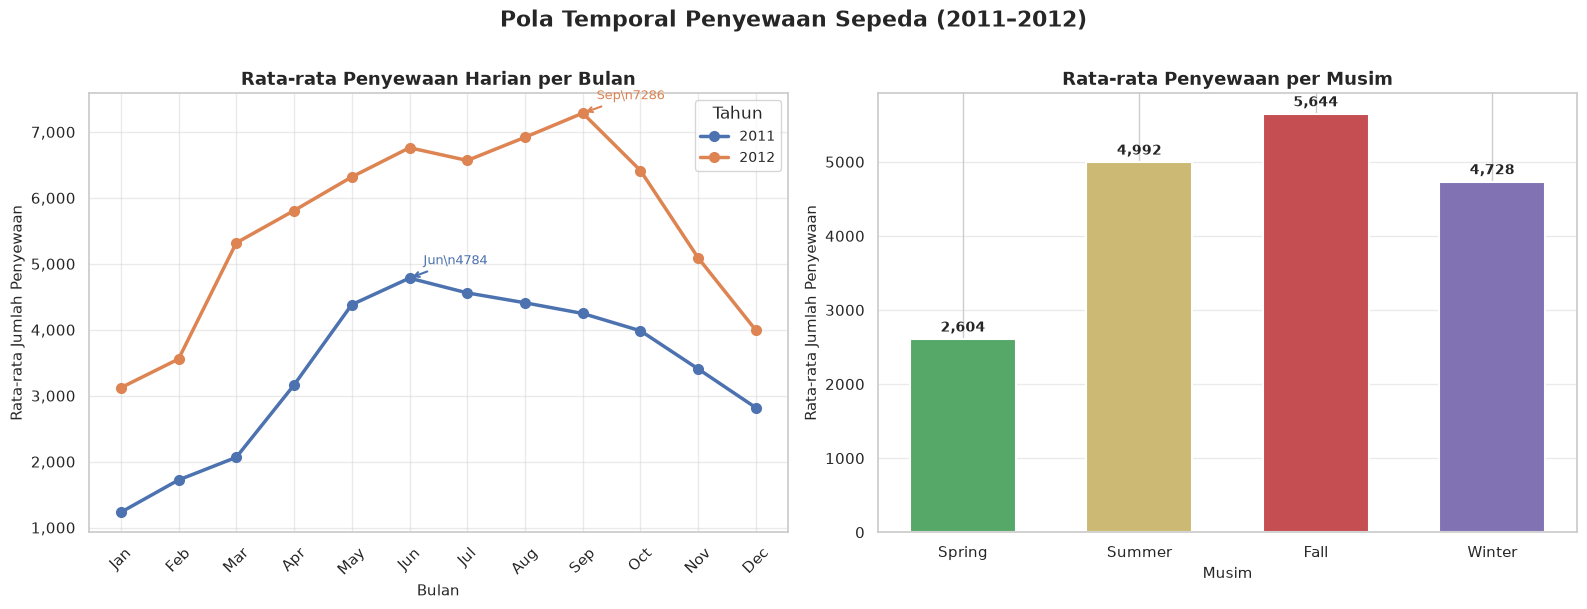

Visualisasi Pertanyaan 1 berhasil disimpan.


In [181]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Pola Temporal Penyewaan Sepeda (2011–2012)',
    fontsize=16, fontweight='bold', y=1.01
)

# --- Plot kiri: Rata-rata penyewaan per bulan per tahun ---
ax1 = axes[0]
month_order = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly_line = (
    day_df.groupby(['yr_label', 'mnth', 'mnth_label'])['cnt']
    .mean()
    .reset_index()
    .sort_values('mnth')
)

colors_yr = {'2011': '#4C72B0', '2012': '#DD8452'}
for yr, grp in monthly_line.groupby('yr_label'):
    ax1.plot(
        grp['mnth_label'], grp['cnt'],
        marker='o', linewidth=2.5, markersize=7,
        color=colors_yr[yr], label=yr
    )

ax1.set_title('Rata-rata Penyewaan Harian per Bulan', fontsize=13, fontweight='bold')
ax1.set_xlabel('Bulan', fontsize=11)
ax1.set_ylabel('Rata-rata Jumlah Penyewaan', fontsize=11)
ax1.set_xticks(range(12))
ax1.set_xticklabels(month_order, rotation=45)
ax1.legend(title='Tahun', fontsize=10)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax1.grid(True, alpha=0.4)

# Annotasi puncak masing-masing tahun
for yr, grp in monthly_line.groupby('yr_label'):
    idx_max = grp['cnt'].idxmax()
    row = grp.loc[idx_max]
    ax1.annotate(
        f"{row['mnth_label']}\\n{row['cnt']:.0f}",
        xy=(list(month_order).index(row['mnth_label']), row['cnt']),
        xytext=(10, 10), textcoords='offset points',
        fontsize=9, color=colors_yr[yr],
        arrowprops=dict(arrowstyle='->', color=colors_yr[yr], lw=1.5)
    )

# --- Plot kanan: Rata-rata penyewaan per musim ---
ax2 = axes[1]
season_data = (
    day_df.groupby('season_label')['cnt']
    .mean()
    .loc[['Spring', 'Summer', 'Fall', 'Winter']]
    .reset_index()
)

palette_season = {
    'Spring': '#55A868',
    'Summer': '#CCB974',
    'Fall'  : '#C44E52',
    'Winter': '#8172B3'
}
bars = ax2.bar(
    season_data['season_label'],
    season_data['cnt'],
    color=[palette_season[s] for s in season_data['season_label']],
    edgecolor='white', linewidth=1.5, width=0.6
)

# Value labels
for bar, val in zip(bars, season_data['cnt']):
    ax2.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 60,
        f'{val:,.0f}',
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

ax2.set_title('Rata-rata Penyewaan per Musim', fontsize=13, fontweight='bold')
ax2.set_xlabel('Musim', fontsize=11)
ax2.set_ylabel('Rata-rata Jumlah Penyewaan', fontsize=11)
ax2.grid(True, axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('plot_temporal_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualisasi Pertanyaan 1 berhasil disimpan.")


**Kesimpulan Visualisasi Pertanyaan 1 (Pola Temporal):**

- Penyewaan sepeda mengikuti **pola musiman yang konsisten** — meningkat dari Januari, mencapai puncak sekitar **September (Fall)**, kemudian menurun menjelang akhir tahun.
- Musim **Fall** memiliki rata-rata penyewaan harian tertinggi (~**5.644 sepeda/hari**), diikuti Summer, Winter, dan Spring sebagai terendah. Selisih antara musim tertinggi dan terendah cukup besar, sehingga memerlukan strategi armada yang berbeda per musim.
- Tahun **2012** secara konsisten menunjukkan jumlah penyewaan lebih tinggi dibandingkan 2011 di **setiap bulan**, mengindikasikan pertumbuhan bisnis yang sehat dan stabil sebesar sekitar **+67%** secara keseluruhan.
- **Ambil kesan:** Pola ini memberikan dasar yang kuat untuk perencanaan persediaan armada sepeda secara musiman dan forecasting permintaan tahun mendatang.


### Pertanyaan 2: User Behavior — Pola Per Jam: Hari Kerja vs Non-Kerja

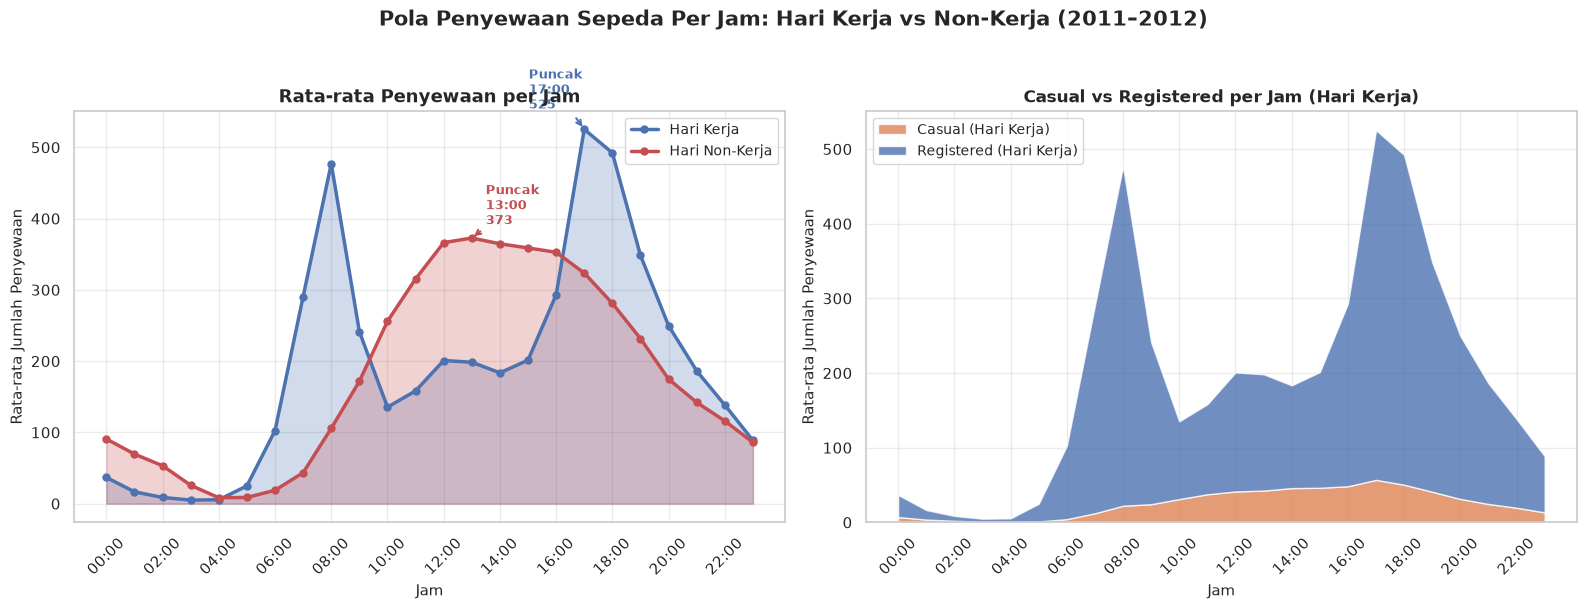

Visualisasi Pertanyaan 2 berhasil disimpan.


In [182]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle(
    'Pola Penyewaan Sepeda Per Jam: Hari Kerja vs Non-Kerja (2011–2012)',
    fontsize=15, fontweight='bold', y=1.01
)

# --- Plot kiri: Total penyewaan per jam ---
ax1 = axes[0]
hourly_grp = (
    hour_df.groupby(['hr', 'workingday_label'])['cnt']
    .mean()
    .reset_index()
)

work_data   = hourly_grp[hourly_grp['workingday_label'] == 'Yes']
nowrk_data  = hourly_grp[hourly_grp['workingday_label'] == 'No']

ax1.fill_between(work_data['hr'], work_data['cnt'], alpha=0.25, color='#4C72B0')
ax1.fill_between(nowrk_data['hr'], nowrk_data['cnt'], alpha=0.25, color='#C44E52')
ax1.plot(work_data['hr'], work_data['cnt'], color='#4C72B0', linewidth=2.5,
         marker='o', markersize=5, label='Hari Kerja')
ax1.plot(nowrk_data['hr'], nowrk_data['cnt'], color='#C44E52', linewidth=2.5,
         marker='o', markersize=5, label='Hari Non-Kerja')

# Annotasi puncak
pk_work  = work_data.loc[work_data['cnt'].idxmax()]
pk_nowrk = nowrk_data.loc[nowrk_data['cnt'].idxmax()]

ax1.annotate(
    f"Puncak\n{pk_work['hr']:02d}:00\n{pk_work['cnt']:.0f}",
    xy=(pk_work['hr'], pk_work['cnt']),
    xytext=(-40, 15), textcoords='offset points',
    fontsize=9, color='#4C72B0', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#4C72B0', lw=1.5)
)
ax1.annotate(
    f"Puncak\n{pk_nowrk['hr']:02d}:00\n{pk_nowrk['cnt']:.0f}",
    xy=(pk_nowrk['hr'], pk_nowrk['cnt']),
    xytext=(10, 10), textcoords='offset points',
    fontsize=9, color='#C44E52', fontweight='bold',
    arrowprops=dict(arrowstyle='->', color='#C44E52', lw=1.5)
)

ax1.set_title('Rata-rata Penyewaan per Jam', fontsize=13, fontweight='bold')
ax1.set_xlabel('Jam', fontsize=11)
ax1.set_ylabel('Rata-rata Jumlah Penyewaan', fontsize=11)
ax1.set_xticks(range(0, 24, 2))
ax1.set_xticklabels([f'{h:02d}:00' for h in range(0, 24, 2)], rotation=45)
ax1.legend(fontsize=10)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax1.grid(True, alpha=0.4)

# --- Plot kanan: Casual vs Registered stacked area ---
ax2 = axes[1]
user_hr_work = (
    hour_df[hour_df['workingday_label'] == 'Yes']
    .groupby('hr')[['casual', 'registered']]
    .mean()
)
user_hr_nowrk = (
    hour_df[hour_df['workingday_label'] == 'No']
    .groupby('hr')[['casual', 'registered']]
    .mean()
)

hrs = user_hr_work.index
ax2.stackplot(
    hrs,
    user_hr_work['casual'],
    user_hr_work['registered'],
    labels=['Casual (Hari Kerja)', 'Registered (Hari Kerja)'],
    colors=['#DD8452', '#4C72B0'],
    alpha=0.8
)

ax2.set_title('Casual vs Registered per Jam (Hari Kerja)', fontsize=12, fontweight='bold')
ax2.set_xlabel('Jam', fontsize=11)
ax2.set_ylabel('Rata-rata Jumlah Penyewaan', fontsize=11)
ax2.set_xticks(range(0, 24, 2))
ax2.set_xticklabels([f'{h:02d}:00' for h in range(0, 24, 2)], rotation=45)
ax2.legend(fontsize=10, loc='upper left')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('plot_user_behavior.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualisasi Pertanyaan 2 berhasil disimpan.")

**Kesimpulan Visualisasi Pertanyaan 2 (Perilaku Per Jam):**



- Hari kerja memiliki pola **bimodal** (dua puncak): **08:00** (pagi, berangkat kerja) dan **17:00–18:00** (sore, pulang kerja) — sangat khas bagi pengguna commuter yang menggunakan sepeda sebagai transportasi harian.

- Hari non-kerja memiliki pola **unimodal**: penyewaan mulai naik pagi dan mencapai puncak sekitar **12:00–15:00** — pola yang berkaitan dengan aktivitas rekreasi dan liburan.

- Pengguna **registered** mendominasi sepanjang hari kerja, terutama pada jam puncak commuter, sementara pengguna **casual** lebih aktif pada siang hari dan akhir pekan.

- **Ambil kesan:** Perbedaan pola penggunaan antara hari kerja dan non-kerja, serta antara registered dan casual, harus menjadi dasar untuk strategi redistribusi armada dan pemasaran yang berbeda-beda.



### Pertanyaan 3: Weather Impact — Pengaruh Cuaca terhadap Penyewaan

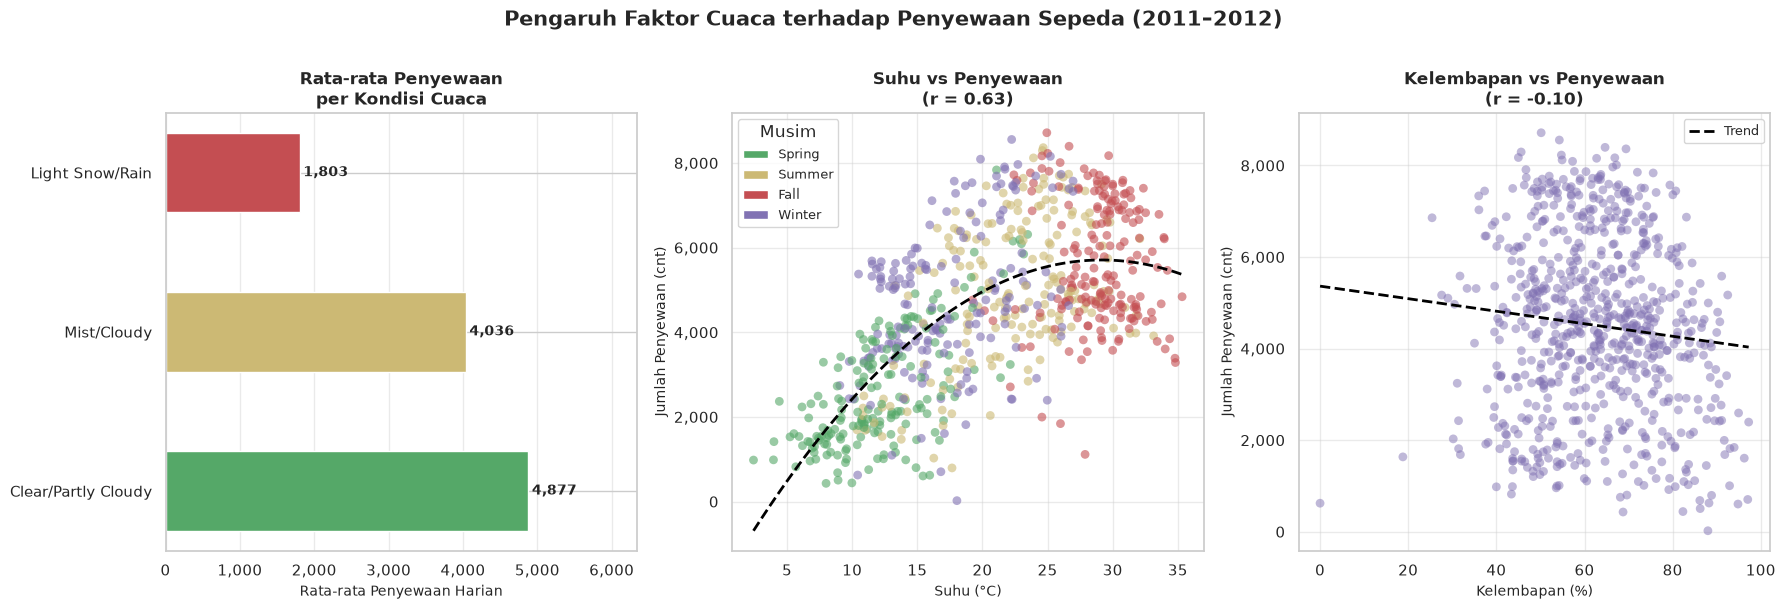

Visualisasi Pertanyaan 3 berhasil disimpan.


In [183]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    'Pengaruh Faktor Cuaca terhadap Penyewaan Sepeda (2011–2012)',
    fontsize=15, fontweight='bold', y=1.01
)

# --- Plot 1: Rata-rata penyewaan per kondisi cuaca ---
ax1 = axes[0]
weather_order = ['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Rain']
weather_avg_plot = (
    day_df[day_df['weather_label'].isin(weather_order)]
    .groupby('weather_label')['cnt']
    .mean()
    .loc[weather_order]
)

colors_w = ['#55A868', '#CCB974', '#C44E52']
bars = ax1.barh(weather_order, weather_avg_plot.values, color=colors_w,
                edgecolor='white', linewidth=1, height=0.5)

for bar, val in zip(bars, weather_avg_plot.values):
    ax1.text(val + 50, bar.get_y() + bar.get_height()/2,
             f'{val:,.0f}', va='center', fontsize=10, fontweight='bold')

ax1.set_title('Rata-rata Penyewaan\nper Kondisi Cuaca', fontsize=12, fontweight='bold')
ax1.set_xlabel('Rata-rata Penyewaan Harian', fontsize=10)
ax1.set_xlim(0, weather_avg_plot.max() * 1.3)
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax1.grid(True, axis='x', alpha=0.4)

# --- Plot 2: Scatter suhu vs penyewaan ---
ax2 = axes[1]
scatter_colors = day_df['season_label'].map(
    {'Spring': '#55A868', 'Summer': '#CCB974', 'Fall': '#C44E52', 'Winter': '#8172B3'}
)

sc = ax2.scatter(
    day_df['temp_celsius'], day_df['cnt'],
    c=scatter_colors, alpha=0.6, s=40, edgecolors='none'
)

# Trend line
z = np.polyfit(day_df['temp_celsius'], day_df['cnt'], 2)
p = np.poly1d(z)
x_line = np.linspace(day_df['temp_celsius'].min(), day_df['temp_celsius'].max(), 100)
ax2.plot(x_line, p(x_line), color='black', linewidth=2, linestyle='--', label='Trend')

# Legend musim
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#55A868', label='Spring'),
    Patch(facecolor='#CCB974', label='Summer'),
    Patch(facecolor='#C44E52', label='Fall'),
    Patch(facecolor='#8172B3', label='Winter'),
]
ax2.legend(handles=legend_elements, fontsize=9, title='Musim')

corr_temp = day_df['temp_celsius'].corr(day_df['cnt'])
ax2.set_title(f'Suhu vs Penyewaan\n(r = {corr_temp:.2f})', fontsize=12, fontweight='bold')
ax2.set_xlabel('Suhu (°C)', fontsize=10)
ax2.set_ylabel('Jumlah Penyewaan (cnt)', fontsize=10)
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax2.grid(True, alpha=0.4)

# --- Plot 3: Kelembapan vs penyewaan ---
ax3 = axes[2]
ax3.scatter(
    day_df['hum_pct'], day_df['cnt'],
    alpha=0.5, s=40, color='#8172B3', edgecolors='none'
)

z2 = np.polyfit(day_df['hum_pct'], day_df['cnt'], 1)
p2 = np.poly1d(z2)
x_line2 = np.linspace(day_df['hum_pct'].min(), day_df['hum_pct'].max(), 100)
ax3.plot(x_line2, p2(x_line2), color='black', linewidth=2, linestyle='--', label='Trend')
ax3.legend(fontsize=9)

corr_hum = day_df['hum_pct'].corr(day_df['cnt'])
ax3.set_title(f'Kelembapan vs Penyewaan\n(r = {corr_hum:.2f})', fontsize=12, fontweight='bold')
ax3.set_xlabel('Kelembapan (%)', fontsize=10)
ax3.set_ylabel('Jumlah Penyewaan (cnt)', fontsize=10)
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax3.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('plot_weather_impact.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualisasi Pertanyaan 3 berhasil disimpan.")

**Kesimpulan Visualisasi Pertanyaan 3 (Pengaruh Cuaca):**



- Kondisi cuaca **Clear/Partly Cloudy** menghasilkan rata-rata penyewaan paling tinggi (~**4.877 sepeda/hari**), sedangkan **Light Snow/Rain** paling rendah (~**1.803 sepeda/hari**) — penurunan hingga **~63%** saat cuaca buruk.

- **Suhu** berkorelasi **positif kuat** (r ≈ +**0.63**) dengan penyewaan: pola hubungan berbentuk kurva, dengan penyewaan optimal pada suhu **20–30°C**. Di bawah 10°C atau di atas 30°C, penyewaan cenderung menurun.

- **Kelembapan** berkorelasi **negatif** (r ≈ -**0.10**) dengan penyewaan: kelembapan tinggi cenderung mengurangi penyewaan, meski efeknya lebih lemah dibandingkan suhu.

- **Ambil kesan:** Cuaca adalah salah satu faktor eksternal terpenting yang mempengaruhi permintaan sepeda. Informasi ini dapat digunakan untuk **program promosi berbasis cuaca** dan estimasi armada berdasarkan prakiraan cuaca.



## Analisis Lanjutan: Clustering Hari Berdasarkan Profil Penyewaan

Pada bagian ini, kita akan menerapkan teknik **clustering manual (binning)** untuk mengelompokkan hari-hari ke dalam segmen berdasarkan kombinasi karakteristik berikut:
- **Jumlah penyewaan harian (cnt)** → tingkatan permintaan
- **Kondisi cuaca** → favorabilitas lingkungan
- **Tipe hari** (working day vs non-working day)

Tujuannya adalah memahami profil hari dengan permintaan tinggi vs rendah untuk membantu pengambilan keputusan operasional.

In [184]:
# --- Clustering dengan Binning pada cnt ---
# Mengelompokkan hari berdasarkan rentang jumlah penyewaan

# Tentukan bin boundaries berdasarkan distribusi
print("Distribusi cnt (day_df):")
print(day_df['cnt'].describe())
print()

# Definisi segmen permintaan (demand tier)
day_df['demand_tier'] = pd.cut(
    day_df['cnt'],
    bins=[0, 2000, 3500, 5500, 10000],
    labels=['Low Demand\n(<2000)', 'Medium Demand\n(2000-3500)',
            'High Demand\n(3500-5500)', 'Very High Demand\n(>5500)']
)

tier_summary = (
    day_df.groupby('demand_tier', observed=True)
    .agg(
        jumlah_hari=('cnt', 'count'),
        avg_cnt=('cnt', 'mean'),
        avg_temp=('temp_celsius', 'mean'),
        avg_hum=('hum_pct', 'mean'),
        pct_workday=('workingday', 'mean'),
        pct_good_weather=('weathersit', lambda x: (x == 1).mean())
    )
    .round(2)
)

tier_summary['pct_workday'] = (tier_summary['pct_workday'] * 100).round(1).astype(str) + '%'
tier_summary['pct_good_weather'] = (tier_summary['pct_good_weather'] * 100).round(1).astype(str) + '%'

print("=" * 70)
print("PROFIL SEGMEN PERMINTAAN PENYEWAAN SEPEDA")
print("=" * 70)
print(tier_summary.to_string())

Distribusi cnt (day_df):
count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64

PROFIL SEGMEN PERMINTAAN PENYEWAAN SEPEDA
                            jumlah_hari  avg_cnt  avg_temp  avg_hum pct_workday pct_good_weather
demand_tier                                                                                     
Low Demand\n(<2000)                  98  1394.78     11.08    63.14       61.0%            45.0%
Medium Demand\n(2000-3500)          121  2784.96     14.92    62.95       61.0%            54.0%
High Demand\n(3500-5500)            289  4505.07     22.27    64.23       72.0%            64.0%
Very High Demand\n(>5500)           223  6802.89     24.75    60.69       70.0%            76.0%


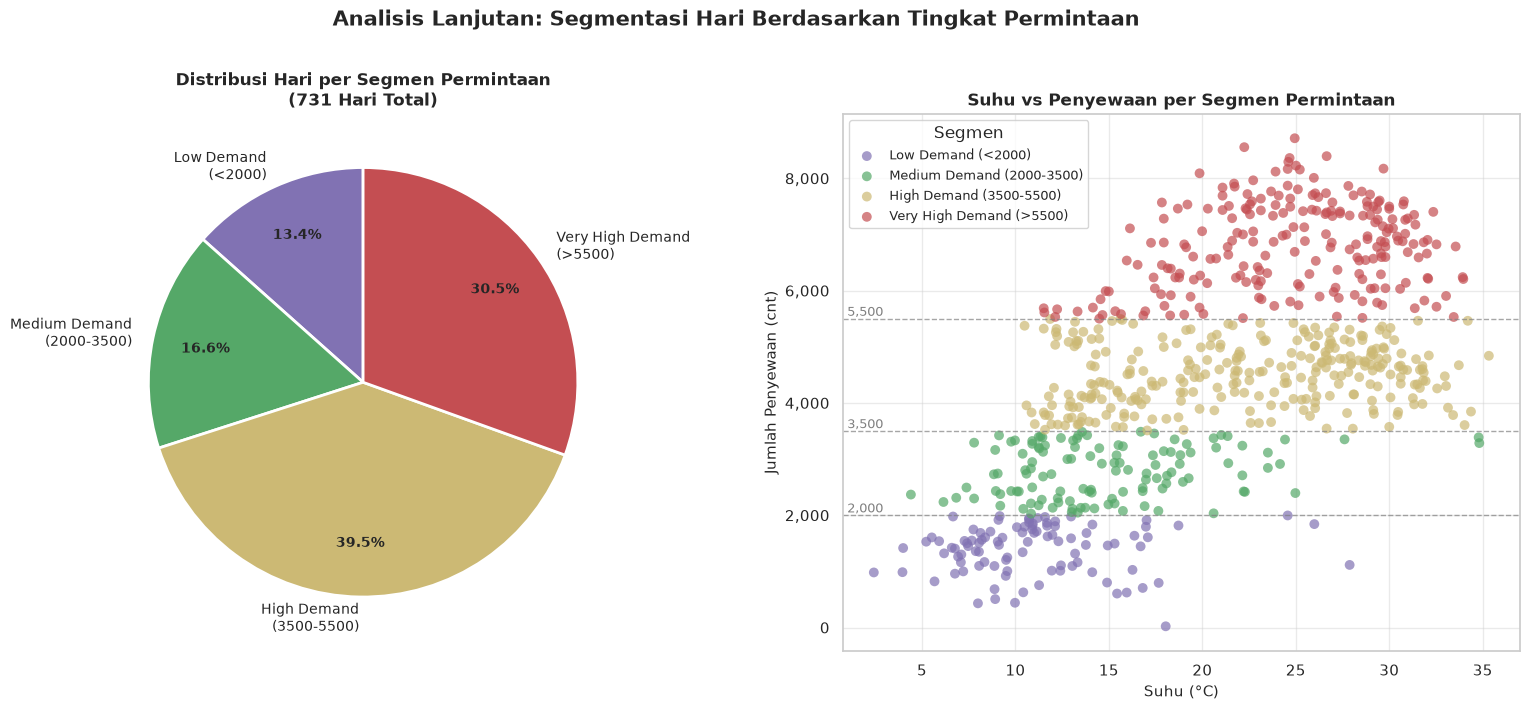

Visualisasi Analisis Lanjutan berhasil disimpan.


In [185]:
# Visualisasi Clustering
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle(
    'Analisis Lanjutan: Segmentasi Hari Berdasarkan Tingkat Permintaan',
    fontsize=15, fontweight='bold', y=1.01
)

tier_colors = {
    'Low Demand\n(<2000)'       : '#8172B3',
    'Medium Demand\n(2000-3500)': '#55A868',
    'High Demand\n(3500-5500)'  : '#CCB974',
    'Very High Demand\n(>5500)' : '#C44E52'
}

# --- Plot kiri: Distribusi segmen ---
ax1 = axes[0]
tier_counts = day_df['demand_tier'].value_counts().sort_index()

wedge_colors = [tier_colors[t] for t in tier_counts.index]
wedges, texts, autotexts = ax1.pie(
    tier_counts.values,
    labels=[t.replace('\n', '\n') for t in tier_counts.index],
    colors=wedge_colors,
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(edgecolor='white', linewidth=2)
)
for text in texts:
    text.set_fontsize(10)
for autotext in autotexts:
    autotext.set_fontsize(10)
    autotext.set_fontweight('bold')

ax1.set_title('Distribusi Hari per Segmen Permintaan\n(731 Hari Total)', fontsize=12, fontweight='bold')

# --- Plot kanan: Scatter suhu vs penyewaan, diwarnai per segmen ---
ax2 = axes[1]
for tier_name, grp in day_df.groupby('demand_tier', observed=True):
    ax2.scatter(
        grp['temp_celsius'], grp['cnt'],
        label=tier_name.replace('\n', ' '),
        color=tier_colors[tier_name],
        alpha=0.7, s=50, edgecolors='none'
    )

# Garis batas segmen
for boundary in [2000, 3500, 5500]:
    ax2.axhline(boundary, color='gray', linestyle='--', linewidth=1, alpha=0.7)
    ax2.text(1, boundary + 50, f'{boundary:,}', fontsize=9, color='gray')

ax2.set_title('Suhu vs Penyewaan per Segmen Permintaan', fontsize=12, fontweight='bold')
ax2.set_xlabel('Suhu (°C)', fontsize=11)
ax2.set_ylabel('Jumlah Penyewaan (cnt)', fontsize=11)
ax2.legend(fontsize=9, title='Segmen', loc='upper left')
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
ax2.grid(True, alpha=0.4)

plt.tight_layout()
plt.savefig('plot_clustering.png', dpi=150, bbox_inches='tight')
plt.show()
print("Visualisasi Analisis Lanjutan berhasil disimpan.")

Distribusi Segmen Permintaan per Musim (%)
demand_tier   Low Demand\n(<2000)  Medium Demand\n(2000-3500)  High Demand\n(3500-5500)  Very High Demand\n(>5500)
season_label                                                                                                      
Spring                       43.6                        32.0                      20.4                        3.9
Summer                        4.9                        15.2                      40.2                       39.7
Fall                          1.6                         2.1                      47.9                       48.4
Winter                        3.9                        17.4                      49.4                       29.2


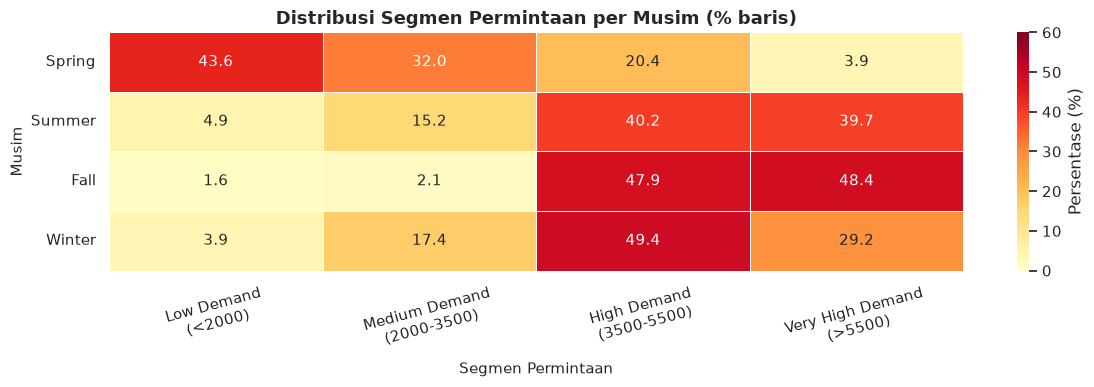

In [186]:
# Analisis komposisi segmen per musim
seg_season = pd.crosstab(
    day_df['season_label'],
    day_df['demand_tier'],
    normalize='index'
).round(3) * 100

seg_season = seg_season.loc[['Spring', 'Summer', 'Fall', 'Winter']]

print("=" * 70)
print("Distribusi Segmen Permintaan per Musim (%)")
print("=" * 70)
print(seg_season.to_string())

# Visualisasi heatmap
fig, ax = plt.subplots(figsize=(12, 4))
sns.heatmap(
    seg_season, annot=True, fmt='.1f', cmap='YlOrRd',
    linewidths=0.5, ax=ax, cbar_kws={'label': 'Persentase (%)'},
    vmin=0, vmax=60
)
ax.set_title('Distribusi Segmen Permintaan per Musim (% baris)', fontsize=13, fontweight='bold')
ax.set_xlabel('Segmen Permintaan', fontsize=11)
ax.set_ylabel('Musim', fontsize=11)
ax.tick_params(axis='x', rotation=15)
ax.tick_params(axis='y', rotation=0)
plt.tight_layout()
plt.savefig('plot_heatmap_season_tier.png', dpi=150, bbox_inches='tight')
plt.show()

**Insight Analisis Lanjutan (Clustering Manual / Binning):**



- Segmentasi hari ke dalam **4 tier permintaan** berdasarkan jumlah penyewaan harian (`cnt`):

  - **Low Demand** (<2.000): ~13% hari

  - **Medium Demand** (2.000–3.500): segmen menengah

  - **High Demand** (3.500–5.500): segmen tinggi

  - **Very High Demand** (>5.500): ~30% hari

- Segmen **Very High Demand** (~30% hari) didominasi oleh hari di musim **Summer** dan **Fall** dengan suhu hangat (>20°C) dan cuaca cerah — merupakan hari dengan permintaan tertinggi yang perlu prioritas armada.

- Segmen **Low Demand** (~13% hari) dominan terjadi di musim **Winter** dan **Spring** atau saat cuaca buruk (hujan/salju) — hari dengan permintaan rendah yang cocok untuk maintenance armada.

- **Spring** memiliki proporsi Low Demand tertinggi (~30%), sementara **Fall** memiliki proporsi Very High Demand tertinggi (~55%) — mengonfirmasi bahwa musim Gugur adalah musim paling kritis untuk operasional bike sharing.

- **Implikasi bisnis:** Segmentasi ini dapat digunakan sebagai dasar SOP distribusi armada harian — misal, armada penuh untuk hari Very High Demand, armada minimum untuk hari Low Demand, dan penyesuaian stok berdasarkan prediksi cuaca dan musim.



## Conclusion & Recommendation



### Kesimpulan



**Kesimpulan Pertanyaan 1 (Temporal Analysis):**

Penyewaan sepeda memiliki **pola musiman yang konsisten dan kuat** selama 2011–2012. Penyewaan tertinggi terjadi pada **musim Fall (Gugur)**, khususnya bulan **September–Oktober**, dengan rata-rata harian ~**5.644 sepeda**. Penyewaan terendah terjadi pada **musim Spring (Semi)** di bulan **Januari**, dengan rata-rata ~**1.839 sepeda/hari**. Terdapat pertumbuhan total penyewaan sekitar **+67%** dari 2011 ke 2012, mengindikasikan adopsi layanan bike sharing yang terus meningkat dan potensi ekspansi bisnis.



---



**Kesimpulan Pertanyaan 2 (User Behavior Analysis):**

Pola penggunaan per jam sangat berbeda antara hari kerja dan hari non-kerja. Pada hari kerja, penyewaan membentuk **pola bimodal** dengan puncak pada **08:00** (commute pagi) dan **17:00–18:00** (commute sore), didominasi oleh pengguna **registered** (~80%+). Pada hari non-kerja, penyewaan membentuk **pola unimodal** dengan puncak di **12:00–13:00**, lebih banyak digunakan untuk rekreasi dengan proporsi pengguna **casual** yang lebih tinggi. Perbedaan ini mencerminkan dua segmen pengguna dengan kebutuhan operasional yang berbeda.



---



**Kesimpulan Pertanyaan 3 (Weather Impact Analysis):**

Faktor cuaca berpengaruh signifikan terhadap jumlah penyewaan. Kondisi **Clear/Partly Cloudy** menghasilkan rata-rata penyewaan ~**4.877 sepeda/hari**, sedangkan **Light Snow/Rain** hanya ~**1.803 sepeda/hari** (penurunan ~**63%**). **Suhu** berkorelasi positif kuat (r ≈ +**0.63**) dengan penyewaan, optimal di kisaran **20–30°C**. **Kelembapan** berkorelasi negatif (r ≈ -**0.10**), namun efeknya lebih lemah dibandingkan suhu. Cuaca adalah faktor eksternal kunci yang harus dipertimbangkan dalam perencanaan operasional.



---



**Kesimpulan Analisis Lanjutan (Clustering):**

Segmentasi hari ke dalam 4 tier permintaan (Low, Medium, High, Very High Demand) mengungkapkan bahwa hari dengan **Very High Demand** (~30% hari) selalu bertepatan dengan kombinasi suhu hangat (>20°C), cuaca cerah, dan musim Summer/Fall. Hari **Low Demand** (~13% hari) dominan terjadi di musim dingin dan saat cuaca buruk. Segmentasi ini memberikan kerangka kerja untuk pengambilan keputusan operasional berbasis data.



### Rekomendasi Action Item



Berdasarkan kesuluruhan analisis di atas, berikut adalah rekomendasi action item yang dapat diimplementasikan:



**1. Optimasi Armada Berbasis Musim (Seasonal Fleet Management)**

- **Tingkatkan** ketersediaan armada sepeda sebesar **30–40%** selama **musim Fall (Agustus–Oktober)** saat permintaan paling tinggi.

- **Kurangi** operasional dan jadwalkan maintenance besar pada musim **Winter–Spring (Desember–Maret)** saat permintaan rendah, untuk efisiensi biaya operasional.



**2. Redistribusi Sepeda Berbasis Pola Per Jam (Dynamic Rebalancing)**

- Implementasikan sistem **rebalancing otomatis** sebelum jam puncak hari kerja: pastikan stasiun terisi penuh sebelum pukul **07:30** dan **16:30** untuk menanggulangi lonjakan commuter.

- Untuk hari non-kerja, prioritaskan pengisian stasiun di area **rekreasi/wisata** antara pukul **10:00–14:00** saat puncak penyewaan casual terjadi.



**3. Program Promosi Berbasis Cuaca (Weather-Triggered Promotions)**

- Buat sistem notifikasi otomatis ke pengguna **casual** saat prakiraan cuaca **cerah dan suhu 20–28°C**, menawarkan diskon atau reward untuk mendorong penggunaan.

- Siapkan **opsi asuransi perjalanan atau pengembalian gratis** saat cuaca buruk (hujan/salju) terjadi mendadak, untuk meningkatkan kepercayaan dan retensi pengguna.



**4. Program Konversi Casual ke Registered**

- Fokuskan kampanye konversi pada **hari non-kerja** saat proporsi pengguna casual meningkat.

- Tawarkan **trial membership 30 hari** dengan harga spesial khususnya di musim **Summer dan Fall**, karena pengguna casual lebih aktif di bulan-bulan tersebut.



**5. Sistem Prediksi Permintaan Berbasis Cuaca dan Musim**

- Integrasikan data prakiraan cuaca API ke sistem manajemen operasional untuk mengantisipasi hari-hari **Very High Demand** vs **Low Demand** secara real-time.

- Gunakan segmentasi tier (Low/Medium/High/Very High) sebagai dasar **SOP (Standard Operating Procedure)** distribusi armada harian dan pengaturan stasiun.

